# 04 -- Promotion lift and ROI

Baseline (what would have sold without the promotion) = the backtest LightGBM model's prediction
for the same week with promotion switched off and price set to regular price. All promo weeks
analysed are out-of-sample. Code: `beverage_demand.promo.analysis`.

* lift = actual - baseline units
* discount investment = (regular - promo price) x units sold
* ROI = incremental units x regular unit margin / discount investment (ROI > 1 = margin-accretive)

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from beverage_demand.config import results, figure
from beverage_demand.db import connect
con = connect(read_only=True)  # the DuckDB warehouse: data/warehouse.duckdb
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

In [2]:
pd.read_csv(results("promo_by_type.csv"))[["pack", "promo_label", "promo_weeks", "avg_discount", "lift_pct", "roi", "net_margin_impact"]]

,pack,promo_label,promo_weeks,avg_discount,lift_pct,roi,net_margin_impact
0,24pk can,Bonus buy (B),8618,0.210,10.461,0.855,-662881.052
1,24pk can,Simple price reduction (S),7313,0.255,25.217,0.936,-563415.686
2,24pk can,Unflagged price cut (U),3782,0.230,4.066,0.542,-413256.628
3,2L,Bonus buy (B),7177,0.303,4.316,0.911,-199200.347
4,2L,Simple price reduction (S),8628,0.329,4.616,0.866,-372157.839
5,2L,Undocumented code (G),381,0.392,4.066,0.882,-21702.416
6,2L,Unflagged price cut (U),3479,0.118,0.272,0.439,-73822.949


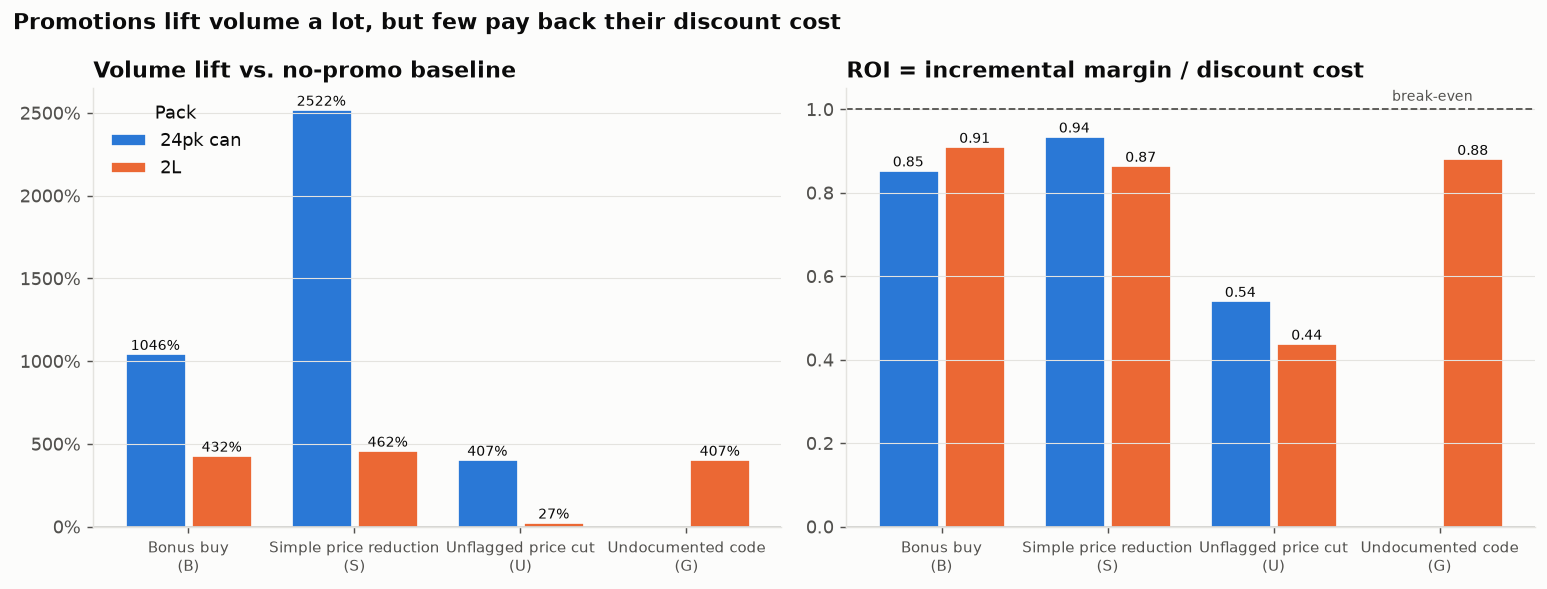

In [3]:
Image(filename=str(figure("promo_lift_roi_by_type.png")))

In [4]:
pd.read_csv(results("promo_by_depth.csv"))[["pack", "depth_bucket", "promo_weeks", "avg_discount", "lift_pct", "roi", "discount_investment", "net_margin_impact"]]

,pack,depth_bucket,promo_weeks,avg_discount,lift_pct,roi,discount_investment,net_margin_impact
0,24pk can,0-10%,2941,0.050,0.580,0.144,5.084e+04,-4.349e+04
1,24pk can,10-20%,7896,0.165,14.511,1.296,3.512e+06,1.040e+06
2,24pk can,20-30%,2919,0.261,14.328,0.891,2.231e+06,-2.430e+05
3,24pk can,30%+,5957,0.391,23.490,0.716,8.437e+06,-2.393e+06
4,2L,0-10%,3511,0.047,0.164,0.927,3.245e+04,-2.358e+03
5,2L,10-20%,2802,0.152,1.426,1.321,1.976e+05,6.346e+04
6,2L,20-30%,3213,0.256,3.322,1.218,5.571e+05,1.217e+05
7,2L,30%+,10139,0.411,5.820,0.813,4.539e+06,-8.497e+05


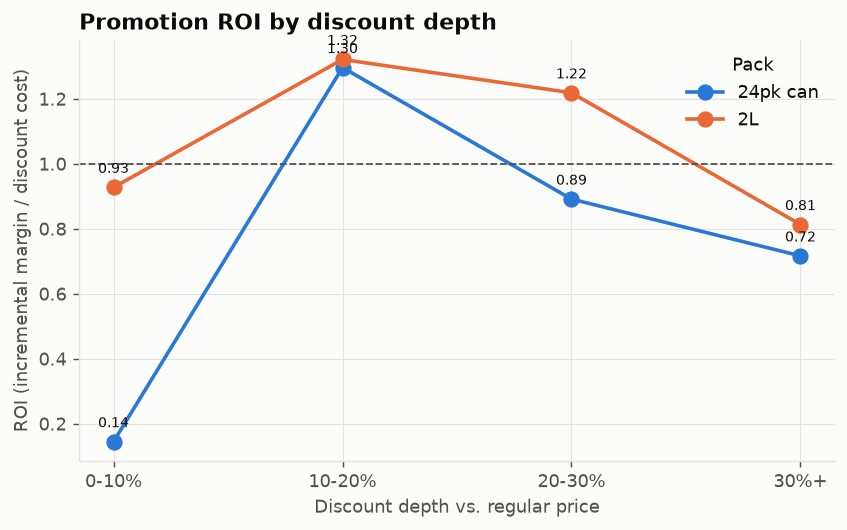

In [5]:
Image(filename=str(figure("promo_roi_by_depth.png")))

**So what:** Promotions move a lot of volume, but on average they do not pay back the margin
given away. The pattern by depth is clear: **10-20% discounts are margin-accretive (ROI above 1),
while 30%+ discounts lose money** -- and that is where about two-thirds of the discount money is
spent. Price cuts that are not tagged as a merchandised promotion (no bonus-buy / sale code) lift
volume far less than tagged ones and have the worst ROI (about 0.5).

## Ranking

In [6]:
Markdown(results("promo_ranking.md").read_text())

# Promotion ranking by ROI

_Generated by `beverage_demand.promo.analysis` (SQL: `sql/analysis/promo_roi.sql`). Out-of-sample backtest period (weeks 328-399); promotion types with at least 50 promoted store-weeks and an average discount of at least 5%; `lift` = volume vs. the no-promo baseline; `net` = gross-margin change vs. not promoting._

## Top 10

| promotion                                                       |   promo_weeks | lift   |   ROI | net      |
|:----------------------------------------------------------------|--------------:|:-------|------:|:---------|
| Private Label 24pk can - Bonus buy (B), 0-10% off               |           221 | +107%  |  3.24 | $1,099   |
| Pepsi 24pk can - Simple price reduction (S), 10-20% off         |           701 | +2915% |  2.01 | $966,392 |
| Private Label 24pk can - Simple price reduction (S), 10-20% off |           312 | +2842% |  1.99 | $29,434  |
| Diet Pepsi 24pk can - Simple price reduction (S), 10-20% off    |           704 | +2029% |  1.89 | $327,237 |
| 7Up 2L - Bonus buy (B), 10-20% off                              |            98 | +181%  |  1.74 | $4,311   |
| Pepsi 2L - Simple price reduction (S), 10-20% off               |           232 | +165%  |  1.58 | $10,866  |
| Coke 2L - Bonus buy (B), 10-20% off                             |           231 | +532%  |  1.55 | $29,643  |
| Diet Pepsi 2L - Simple price reduction (S), 10-20% off          |           237 | +137%  |  1.53 | $5,164   |
| Diet Coke 2L - Bonus buy (B), 10-20% off                        |           203 | +459%  |  1.52 | $20,158  |
| Pepsi 2L - Bonus buy (B), 20-30% off                            |           274 | +478%  |  1.5  | $36,154  |

## Bottom 10

| promotion                                                    |   promo_weeks | lift   |   ROI | net     |
|:-------------------------------------------------------------|--------------:|:-------|------:|:--------|
| Diet Coke 24pk can - Unflagged price cut (U), 0-10% off      |           179 | +4%    | -0.22 | $-3,002 |
| Diet Pepsi 24pk can - Unflagged price cut (U), 0-10% off     |           147 | -1%    | -0.29 | $-1,977 |
| Diet Pepsi 2L - Unflagged price cut (U), 10-20% off          |           155 | -13%   | -0.3  | $-2,908 |
| Coke 24pk can - Unflagged price cut (U), 0-10% off           |           146 | -12%   | -0.36 | $-3,254 |
| Diet Coke 2L - Unflagged price cut (U), 0-10% off            |           343 | -8%    | -0.53 | $-5,901 |
| 7Up 24pk can - Unflagged price cut (U), 0-10% off            |           130 | -12%   | -0.53 | $-906   |
| Private Label 24pk can - Unflagged price cut (U), 10-20% off |           254 | -21%   | -0.57 | $-636   |
| Diet Pepsi 2L - Bonus buy (B), 0-10% off                     |            78 | -28%   | -0.68 | $-794   |
| Diet Pepsi 2L - Unflagged price cut (U), 0-10% off           |           477 | -15%   | -0.69 | $-5,608 |
| Private Label 24pk can - Unflagged price cut (U), 20-30% off |           131 | -67%   | -2.67 | $-597   |


## Post-promotion dip and cannibalisation

In [7]:
pd.read_csv(results("promo_by_series.csv"))[["series", "avg_discount", "lift_pct", "roi", "avg_competitor_volume_change_pct", "competitors_measured"]]

,series,avg_discount,lift_pct,roi,avg_competitor_volume_change_pct,competitors_measured
0,7Up | 24pk can,0.264,29.763,0.846,-0.086,5
1,7Up | 2L,0.282,3.204,0.951,-0.039,5
2,Coke | 24pk can,0.232,13.502,0.738,-0.167,4
3,Coke | 2L,0.284,3.860,0.829,-0.062,5
4,Diet Coke | 24pk can,0.232,11.340,0.707,0.038,3
5,Diet Coke | 2L,0.286,3.147,0.793,0.009,5
6,Diet Pepsi | 24pk can,0.220,11.988,0.978,NaN,0
7,Diet Pepsi | 2L,0.275,3.429,0.887,NaN,0
8,Pepsi | 24pk can,0.219,15.956,1.038,-0.030,4
9,Pepsi | 2L,0.282,4.347,0.955,-0.051,4


**So what:** After a national-brand 24-pack promotion, volume dips by roughly 8-18% the following
week (shoppers stocked up; see `promo_effects.csv`); 2-litre dips are small, and private-label
24-packs show no dip. Most brands' promotions also take volume from competitors in the same pack
-- up to about 17% of competitors' volume for Coke 24-packs -- so part of the lift is brand
switching, not new category demand.